# Сбор и подготовка данных: датасет scrap_price (цены автомобилей)
Шаги: 1) импорт, 2) пропуски и выбросы, 3) новые признаки и кодирование, 4) масштабирование.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sns.set_theme(style="whitegrid")
CSV_PATH = "scrap_price.csv"   # путь к файлу
OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)


def save_show(name):
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=110)
    plt.show()

## 1. Импорт датасета

In [4]:
df = pd.read_csv(CSV_PATH)
print("Размер:", df.shape)
print(df.head())
print(df.info())

Размер: (205, 26)
   ID  symboling                      name fueltypes aspiration doornumbers  \
0   1          3        alfa-romero giulia       gas        std         two   
1   2          3       alfa-romero stelvio       gas        std         two   
2   3          1  alfa-romero Quadrifoglio       gas        std         two   
3   4          2               audi 100 ls       gas        std        four   
4   5          2                audi 100ls       gas        std        four   

       carbody drivewheels enginelocation  wheelbase  ...  enginesize  \
0  convertible         rwd          front       88.6  ...         130   
1  convertible         rwd          front       88.6  ...         130   
2    hatchback         rwd          front       94.5  ...         152   
3        sedan         fwd          front       99.8  ...         109   
4        sedan         4wd          front       99.4  ...         136   

   fuelsystem  boreratio  stroke compressionratio horsepower  peakrp

In [5]:
# ID — служебный столбец, для анализа не нужен
df = df.drop(columns=["ID"])
print("Полных дубликатов строк:", df.duplicated().sum())

num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Числовые:", num_cols)
print("Категориальные:", cat_cols)

Полных дубликатов строк: 0
Числовые: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
Категориальные: ['name', 'fueltypes', 'aspiration', 'doornumbers', 'carbody', 'drivewheels', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


## 2. Пропуски и аномальные значения
### 2.1 Пропуски

Пропусков не обнаружено


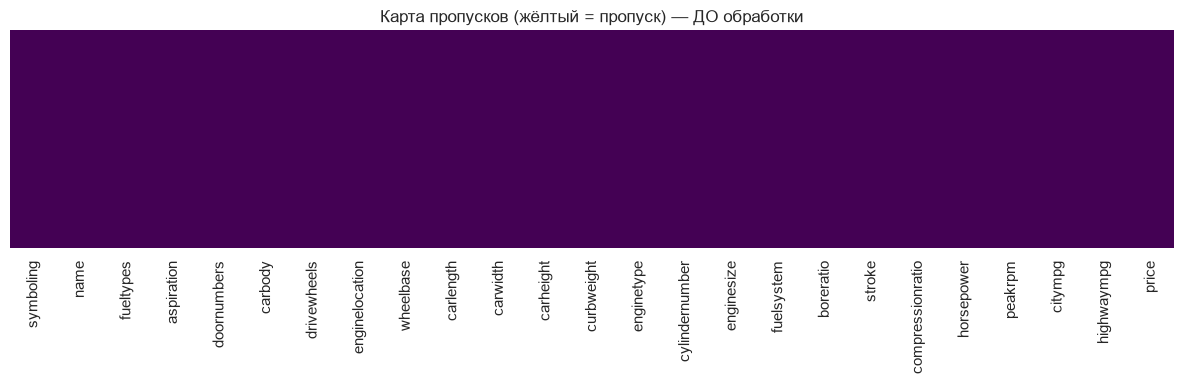

In [6]:
missing = df.isna().sum()
print(missing[missing > 0] if missing.sum() else "Пропусков не обнаружено")

plt.figure(figsize=(12, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Карта пропусков (жёлтый = пропуск) — ДО обработки")
save_show("01_missing_before")

In [7]:
# Универсальное заполнение (сработает, если в данных появятся пропуски):
# числовые — медианой, категориальные — модой
for c in num_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])
print("Пропусков после заполнения:", int(df.isna().sum().sum()))

Пропусков после заполнения: 0


### 2.2 Выбросы: описательная статистика, распределения, boxplot

In [8]:
print(df[num_cols].describe().T)
print("\nАсимметрия:\n", df[num_cols].skew().round(2))

                  count          mean          std      min      25%  \
symboling         205.0      0.834146     1.245307    -2.00     0.00   
wheelbase         205.0     98.756585     6.021776    86.60    94.50   
carlength         205.0    174.049268    12.337289   141.10   166.30   
carwidth          205.0     65.907805     2.145204    60.30    64.10   
carheight         205.0     53.724878     2.443522    47.80    52.00   
curbweight        205.0   2555.565854   520.680204  1488.00  2145.00   
enginesize        205.0    126.907317    41.642693    61.00    97.00   
boreratio         205.0      3.329756     0.270844     2.54     3.15   
stroke            205.0      3.255415     0.313597     2.07     3.11   
compressionratio  205.0     10.142537     3.972040     7.00     8.60   
horsepower        205.0    104.117073    39.544167    48.00    70.00   
peakrpm           205.0   5125.121951   476.985643  4150.00  4800.00   
citympg           205.0     25.219512     6.542142    13.00    1

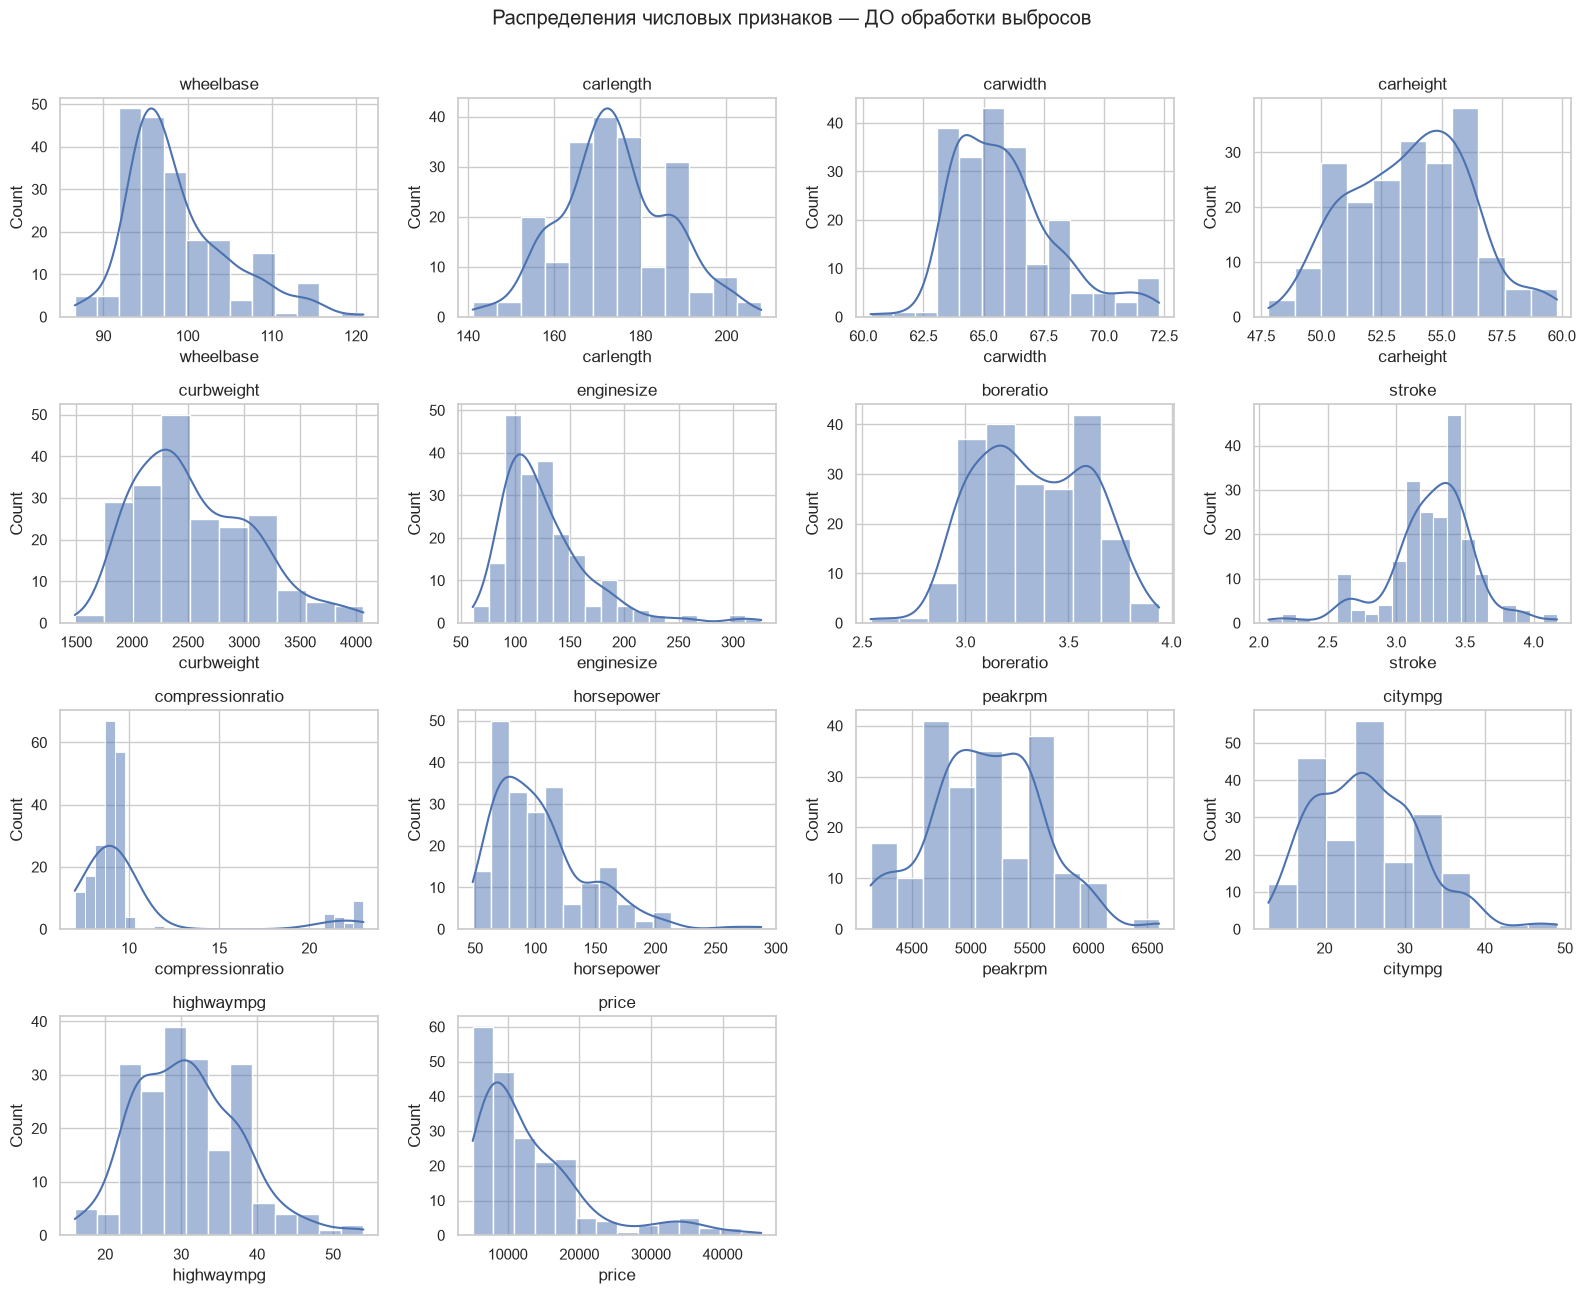

In [9]:
plot_cols = [c for c in num_cols if c != "symboling"]
n = len(plot_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
for ax, c in zip(axes.ravel(), plot_cols):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("Распределения числовых признаков — ДО обработки выбросов", y=1.01)
save_show("02_hist_before")

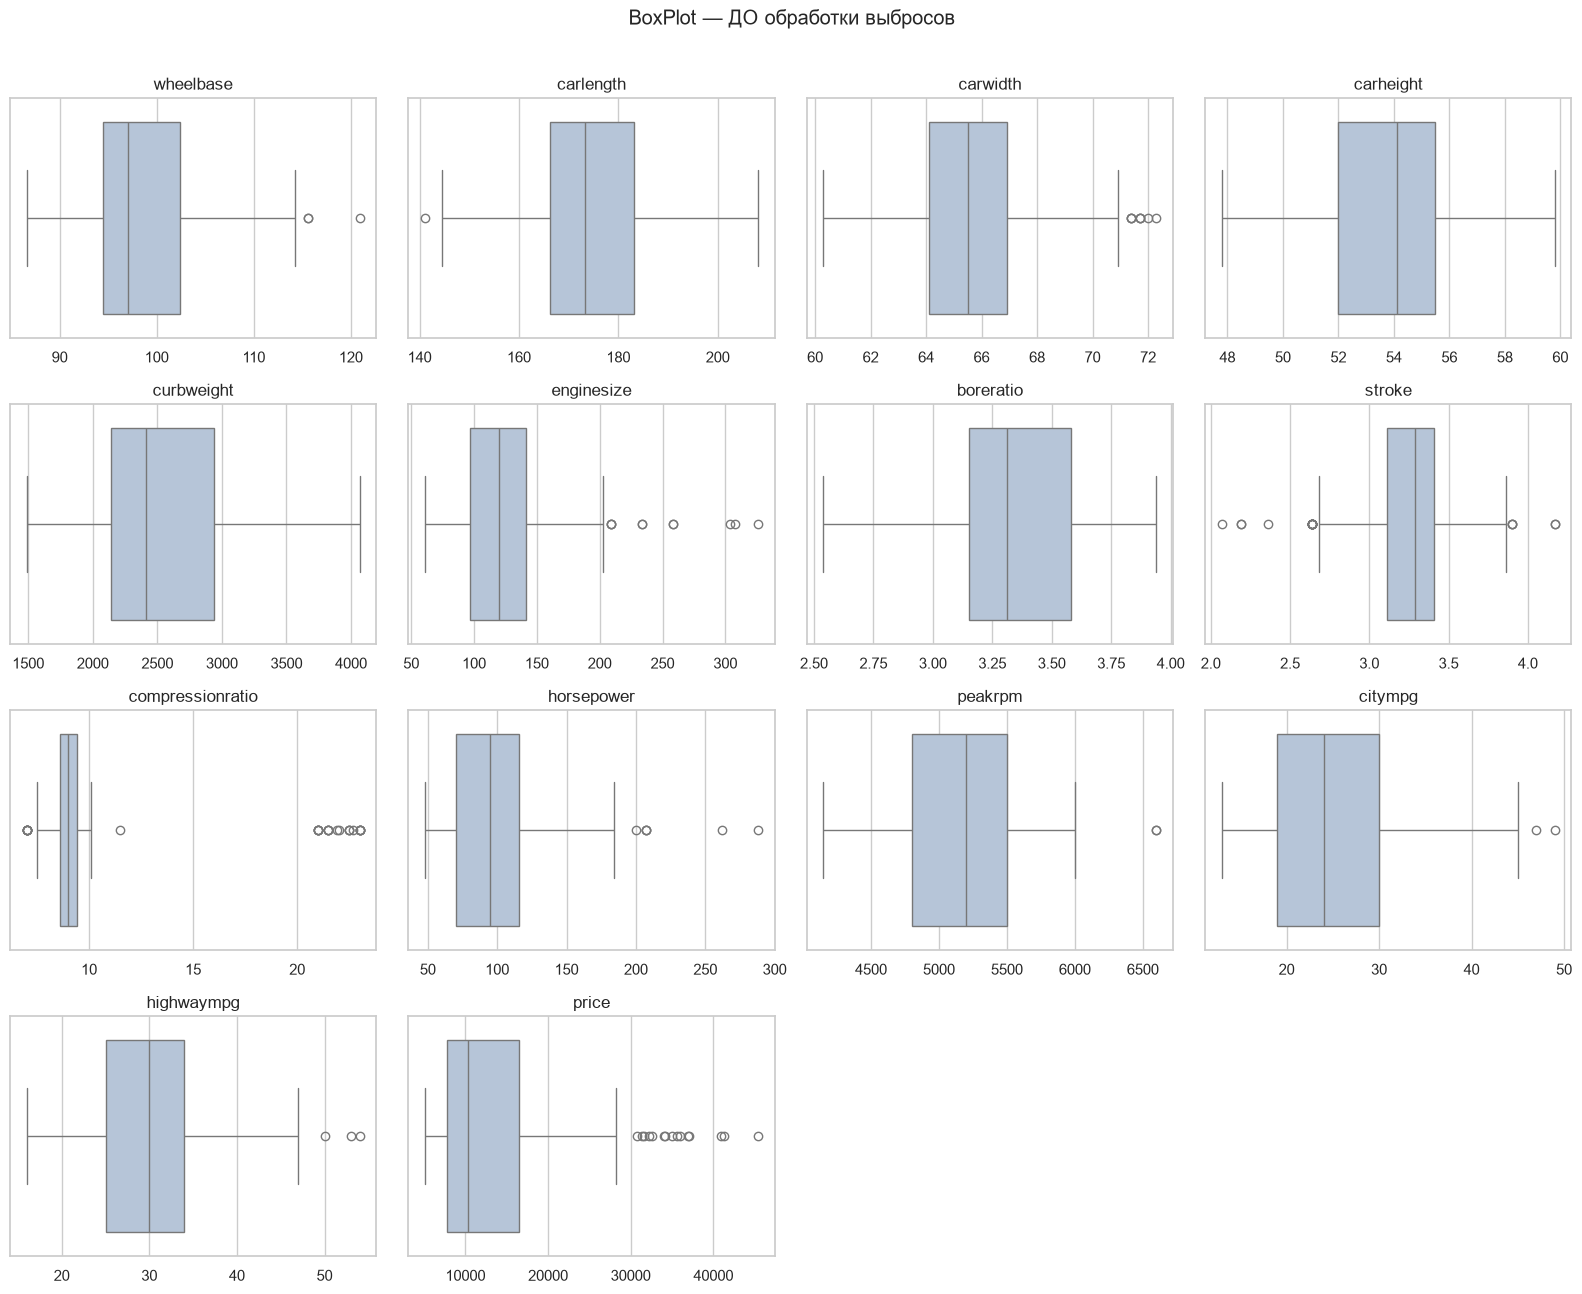

In [10]:
def boxplots(data, title, fname):
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
    for ax, c in zip(axes.ravel(), plot_cols):
        sns.boxplot(x=data[c], ax=ax, color="lightsteelblue")
        ax.set_title(c)
        ax.set_xlabel("")
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.suptitle(title, y=1.01)
    save_show(fname)


boxplots(df, "BoxPlot — ДО обработки выбросов", "03_box_before")

In [11]:
# Статистический метод: правило межквартильного размаха (IQR)
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def outlier_report(data):
    rows = []
    for c in plot_cols:
        lo, hi = iqr_bounds(data[c])
        cnt = int(((data[c] < lo) | (data[c] > hi)).sum())
        rows.append((c, round(lo, 2), round(hi, 2), cnt))
    return pd.DataFrame(rows, columns=["признак", "нижняя граница", "верхняя граница", "выбросов"])


print(outlier_report(df).to_string(index=False))

# Дополнительно: z-score (|z|>3)
z = (df[plot_cols] - df[plot_cols].mean()) / df[plot_cols].std()
print("\nВыбросы по z-score (|z|>3):")
print((z.abs() > 3).sum()[lambda s: s > 0])

         признак  нижняя граница  верхняя граница  выбросов
       wheelbase           82.65           114.25         3
       carlength          141.10           208.30         1
        carwidth           59.90            71.10         8
       carheight           46.75            60.75         0
      curbweight          960.00          4120.00         0
      enginesize           31.00           207.00        10
       boreratio            2.50             4.23         0
          stroke            2.66             3.86        20
compressionratio            7.40            10.60        28
      horsepower            1.00           185.00         6
         peakrpm         3750.00          6550.00         2
         citympg            2.50            46.50         2
      highwaympg           11.50            47.50         3
           price        -5284.50         29575.50        15

Выбросы по z-score (|z|>3):
wheelbase           1
enginesize          5
stroke              3
compr

In [12]:
# Устранение: винзоризация (обрезка значений по границам IQR).
# Строки не удаляем — выборка маленькая (205 записей).
# Повторяем, пока по пересчитанным границам выбросов не останется.
df_raw = df.copy()
for it in range(10):
    changed = 0
    for c in plot_cols:
        lo, hi = iqr_bounds(df[c])
        clipped = df[c].clip(lo, hi)
        changed += int((clipped != df[c]).sum())
        df[c] = clipped
    print(f"Итерация {it + 1}: изменено значений = {changed}")
    if changed == 0:
        break

Итерация 1: изменено значений = 98
Итерация 2: изменено значений = 0


         признак  нижняя граница  верхняя граница  выбросов
       wheelbase           82.65           114.25         0
       carlength          141.10           208.30         0
        carwidth           59.90            71.10         0
       carheight           46.75            60.75         0
      curbweight          960.00          4120.00         0
      enginesize           31.00           207.00         0
       boreratio            2.50             4.23         0
          stroke            2.66             3.86         0
compressionratio            7.40            10.60         0
      horsepower            1.00           185.00         0
         peakrpm         3750.00          6550.00         0
         citympg            2.50            46.50         0
      highwaympg           11.50            47.50         0
           price        -5284.50         29575.50         0


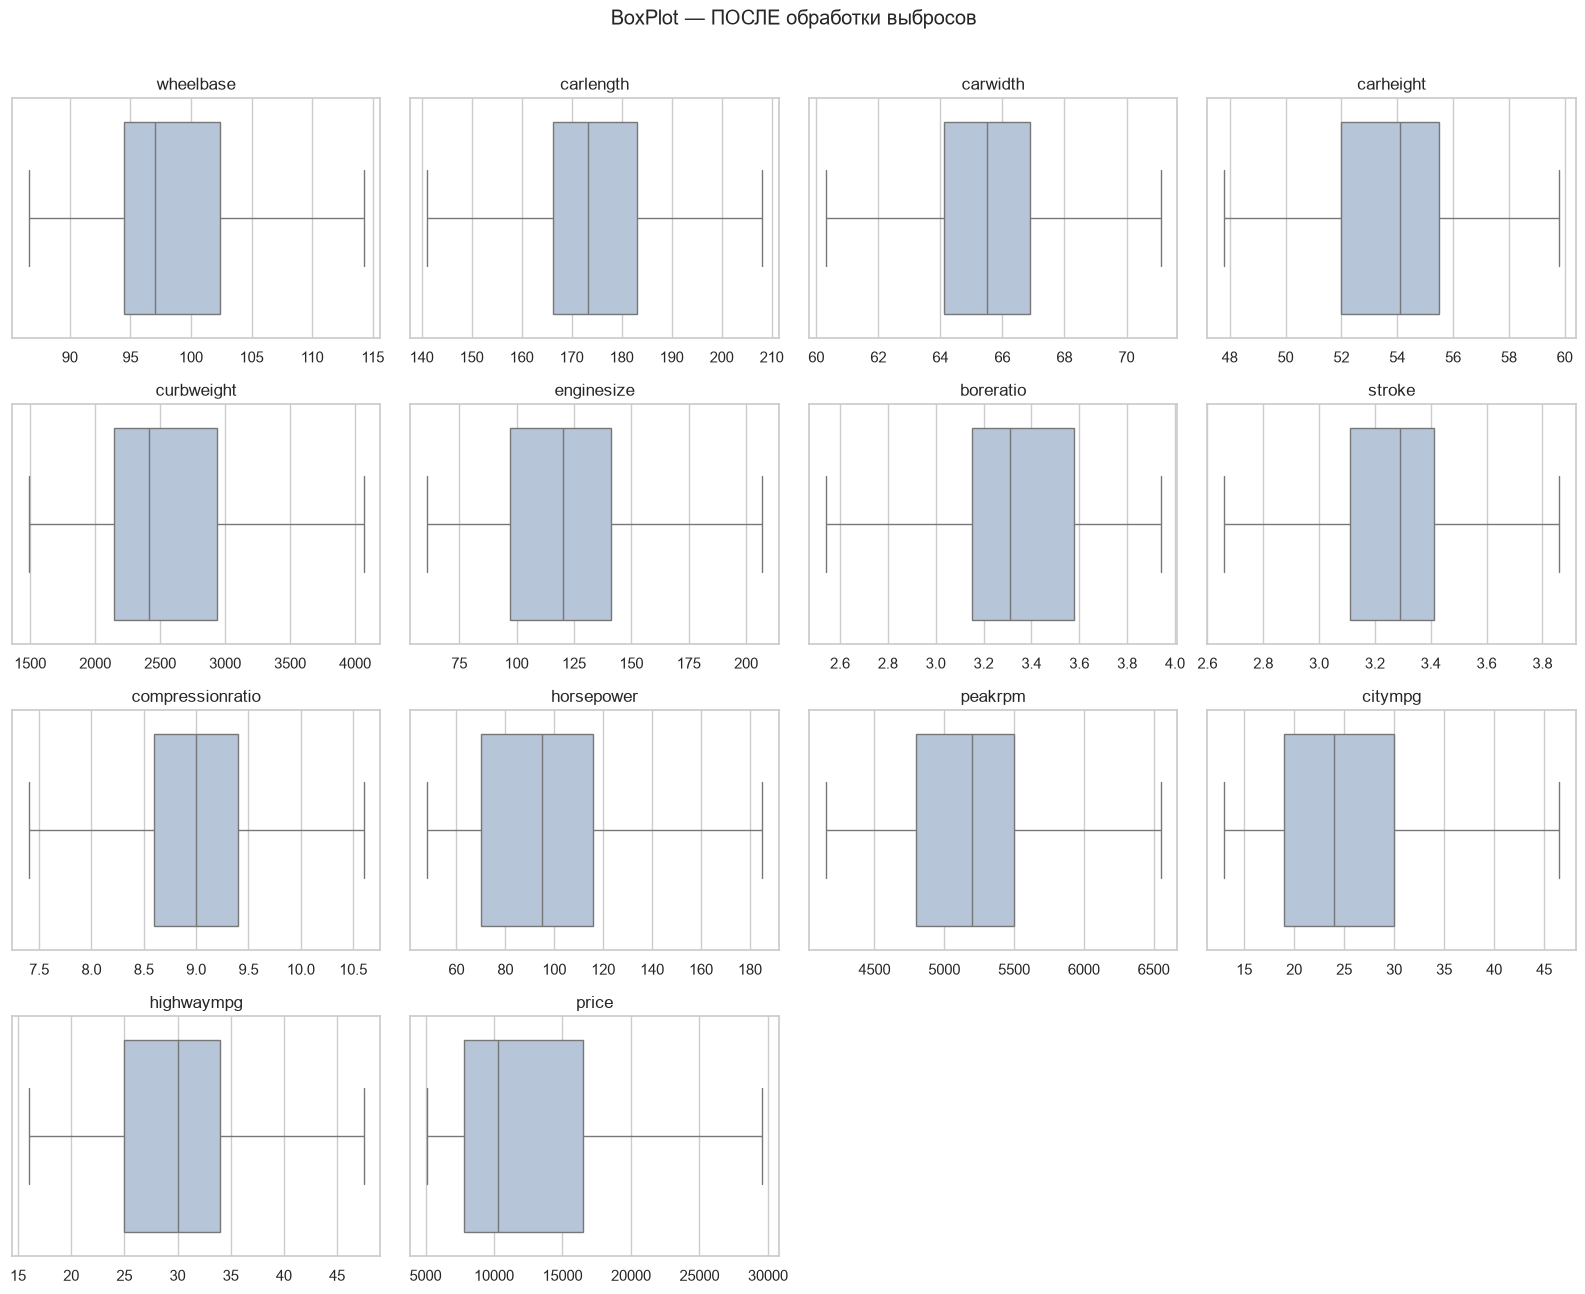

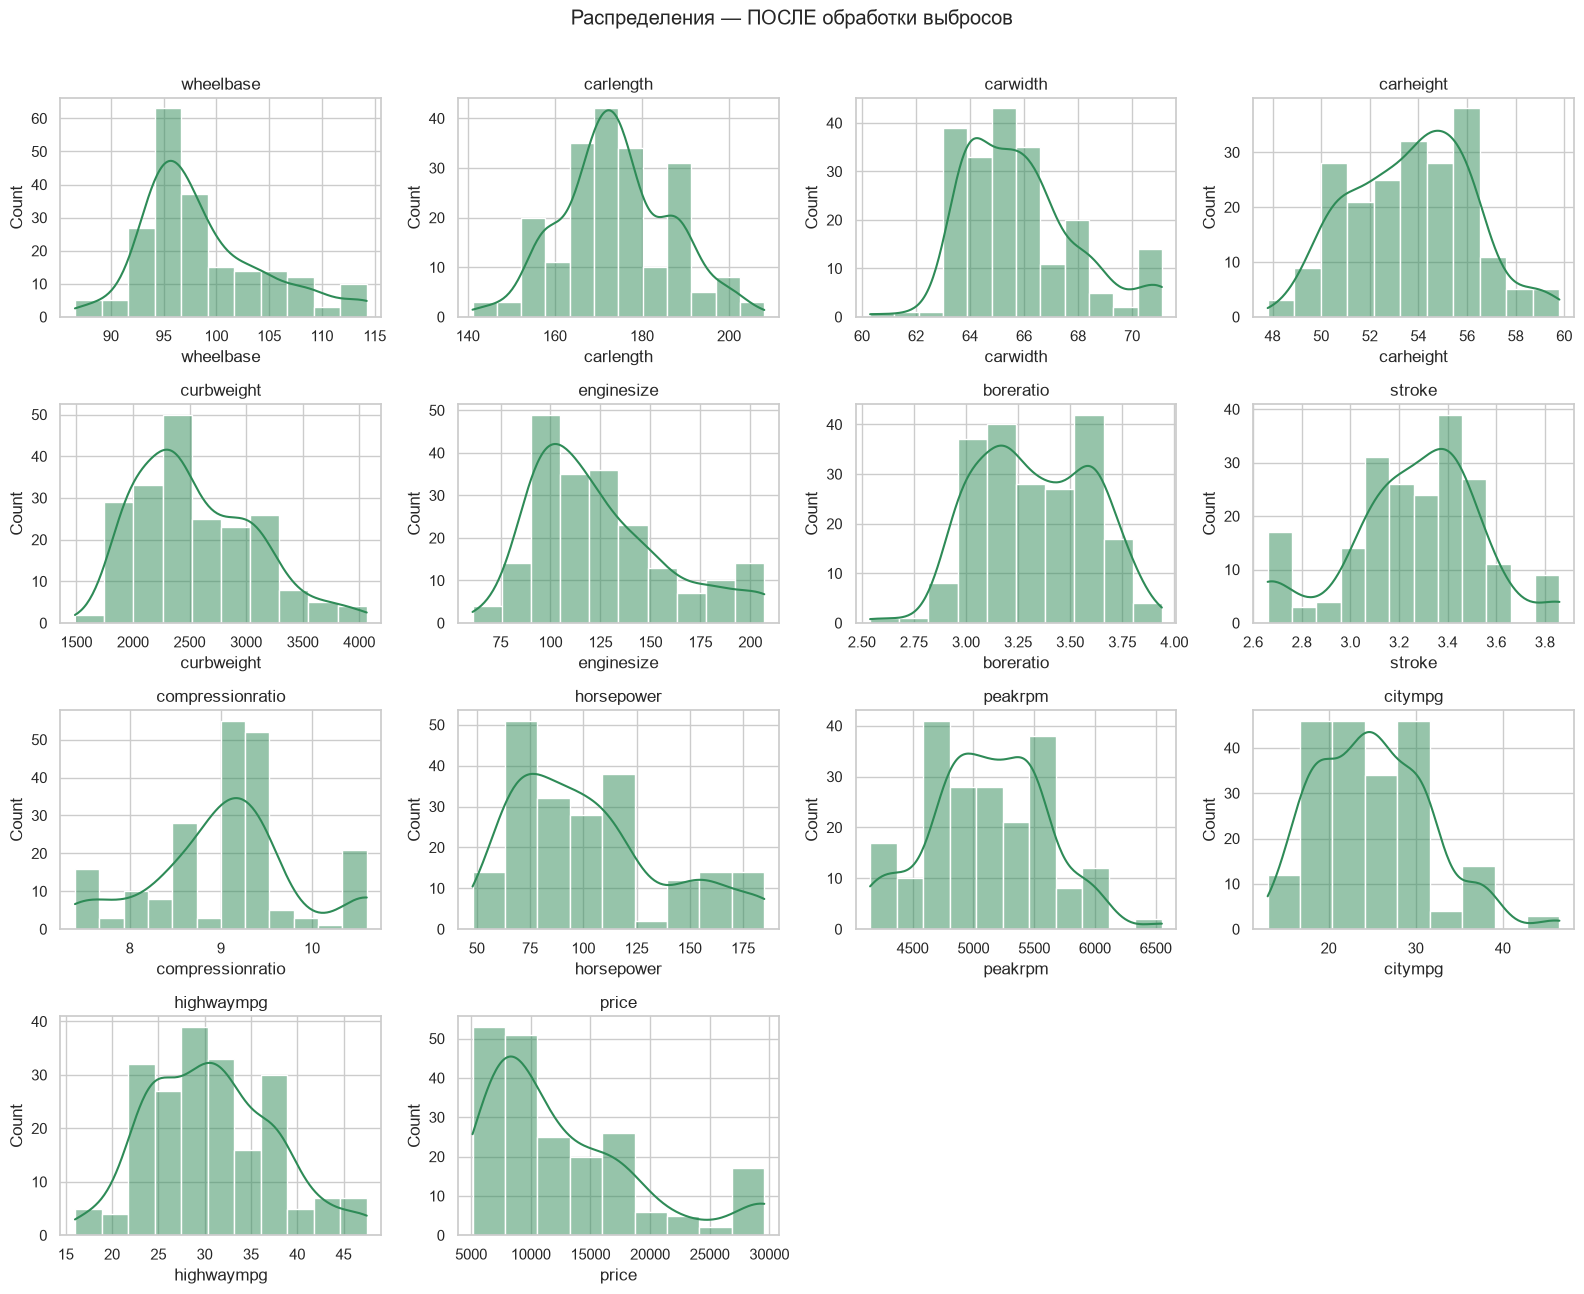

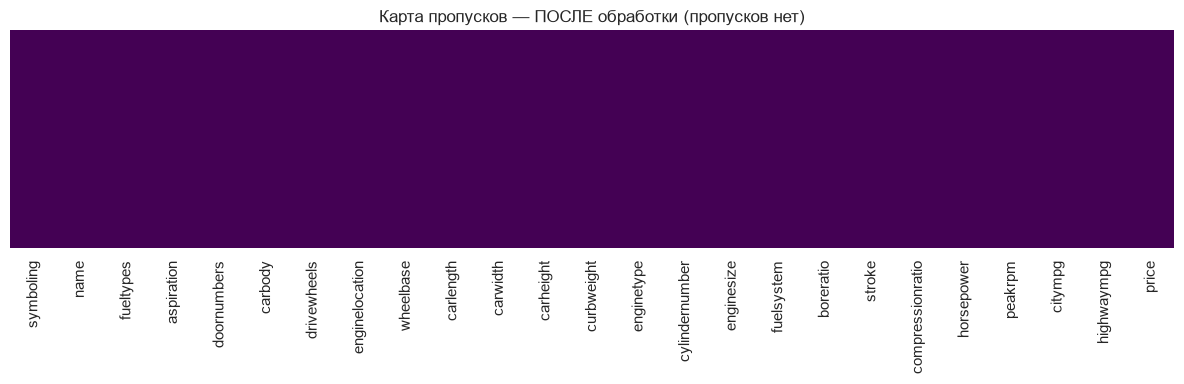

In [13]:
# Проверка графиками и таблицей
print(outlier_report(df).to_string(index=False))
assert outlier_report(df)["выбросов"].sum() == 0

boxplots(df, "BoxPlot — ПОСЛЕ обработки выбросов", "04_box_after")

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
for ax, c in zip(axes.ravel(), plot_cols):
    sns.histplot(df[c], kde=True, ax=ax, color="seagreen")
    ax.set_title(c)
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("Распределения — ПОСЛЕ обработки выбросов", y=1.01)
save_show("05_hist_after")

plt.figure(figsize=(12, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Карта пропусков — ПОСЛЕ обработки (пропусков нет)")
save_show("06_missing_after")

## 3. Новые признаки и кодирование категориальных
### 3.1 Очистка категорий и генерация признаков

In [14]:
# Бренд из названия + исправление опечаток в исходных данных
df["brand"] = df["name"].str.split().str[0].str.lower().replace({
    "maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
    "vokswagen": "volkswagen", "vw": "volkswagen",
})
print(df["brand"].value_counts())

# Новые числовые признаки
df["power_to_weight"] = df["horsepower"] / df["curbweight"]                   # л.с. на фунт массы
df["avg_mpg"] = 0.55 * df["citympg"] + 0.45 * df["highwaympg"]                # комбинированный расход
df["car_volume"] = df["carlength"] * df["carwidth"] * df["carheight"] / 1e6   # габаритный объём
df["engine_per_weight"] = df["enginesize"] / df["curbweight"]                 # литраж на массу

# Порядковое кодирование числа цилиндров (слова -> числа)
cyl_map = {"two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "eight": 8, "twelve": 12}
df["cylinders"] = df["cylindernumber"].map(cyl_map)

# Бинаризация
df["is_gas"] = (df["fueltypes"] == "gas").astype(int)
df["is_turbo"] = (df["aspiration"] == "turbo").astype(int)
df["is_four_door"] = (df["doornumbers"] == "four").astype(int)
df["engine_rear"] = (df["enginelocation"] == "rear").astype(int)
df["risky"] = (df["symboling"] > 0).astype(int)     # symboling>0 — страховщик считает авто более рискованным
df["premium_brand"] = df["brand"].isin(["bmw", "jaguar", "porsche", "audi", "volvo", "saab", "mercedes-benz"]).astype(int)

brand
toyota         32
nissan         18
mazda          17
honda          13
mitsubishi     13
subaru         12
volkswagen     12
peugeot        11
volvo          11
dodge           9
bmw             8
buick           8
audi            7
plymouth        7
saab            6
porsche         5
isuzu           4
alfa-romero     3
chevrolet       3
jaguar          3
renault         2
mercury         1
Name: count, dtype: int64


### 3.2 One-Hot Encoding

In [15]:
ohe_cols = ["carbody", "drivewheels", "enginetype", "fuelsystem", "brand"]
df_enc = pd.get_dummies(df, columns=ohe_cols, drop_first=False, dtype=int)

# Удаляем исходные текстовые столбцы, заменённые закодированными
df_enc = df_enc.drop(columns=["name", "fueltypes", "aspiration", "doornumbers",
                              "enginelocation", "cylindernumber"])
print("Размер после кодирования:", df_enc.shape)
print(df_enc.dtypes.value_counts())

# Проверка: все столбцы числовые, пропусков нет
assert all(pd.api.types.is_numeric_dtype(t) for t in df_enc.dtypes)
assert df_enc.isna().sum().sum() == 0

Размер после кодирования: (205, 71)
int64      57
float64    14
Name: count, dtype: int64


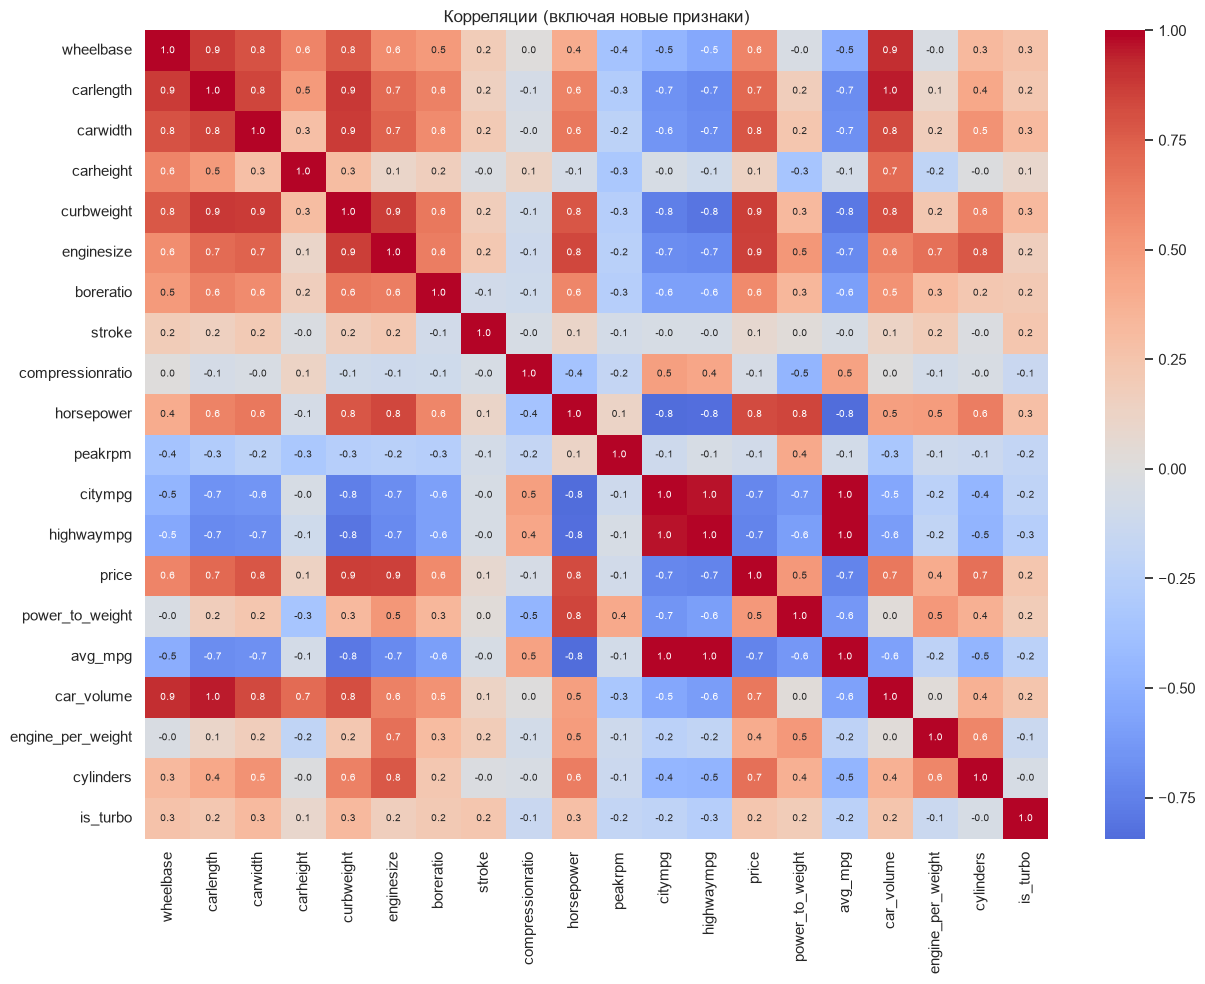

In [16]:
# Тепловая карта корреляций для числовых признаков
corr_cols = plot_cols + ["power_to_weight", "avg_mpg", "car_volume", "engine_per_weight",
                         "cylinders", "is_turbo"]
plt.figure(figsize=(13, 10))
sns.heatmap(df_enc[corr_cols].corr(), annot=True, fmt=".1f", cmap="coolwarm",
            center=0, annot_kws={"size": 7})
plt.title("Корреляции (включая новые признаки)")
save_show("07_corr_heatmap")

## 4. Стандартизация и нормализация
Масштабируем только непрерывные признаки; бинарные и OHE-столбцы оставляем как есть.
Целевую переменную `price` не стандартизируем вместе с признаками.

In [17]:
binary_like = [c for c in df_enc.columns
               if df_enc[c].nunique() <= 2 and set(df_enc[c].unique()) <= {0, 1}]
cont_cols = [c for c in df_enc.columns
             if c not in binary_like and c != "price"]
print("Масштабируем:", cont_cols)

# Стандартизация: (x - mean) / std
df_std = df_enc.copy()
df_std[cont_cols] = StandardScaler().fit_transform(df_enc[cont_cols])

# Нормализация Min-Max в [0, 1]
df_mm = df_enc.copy()
df_mm[cont_cols] = MinMaxScaler().fit_transform(df_enc[cont_cols])

print("\nСтандартизация: mean≈0, std≈1")
print(df_std[cont_cols].agg(["mean", "std"]).T.round(3).head(8))
print("\nMin-Max: min=0, max=1")
print(df_mm[cont_cols].agg(["min", "max"]).T.round(3).head(8))

Масштабируем: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'power_to_weight', 'avg_mpg', 'car_volume', 'engine_per_weight', 'cylinders']

Стандартизация: mean≈0, std≈1
            mean    std
symboling    0.0  1.002
wheelbase   -0.0  1.002
carlength    0.0  1.002
carwidth     0.0  1.002
carheight   -0.0  1.002
curbweight   0.0  1.002
enginesize  -0.0  1.002
boreratio    0.0  1.002

Min-Max: min=0, max=1
            min  max
symboling   0.0  1.0
wheelbase   0.0  1.0
carlength   0.0  1.0
carwidth    0.0  1.0
carheight   0.0  1.0
curbweight  0.0  1.0
enginesize  0.0  1.0
boreratio   0.0  1.0


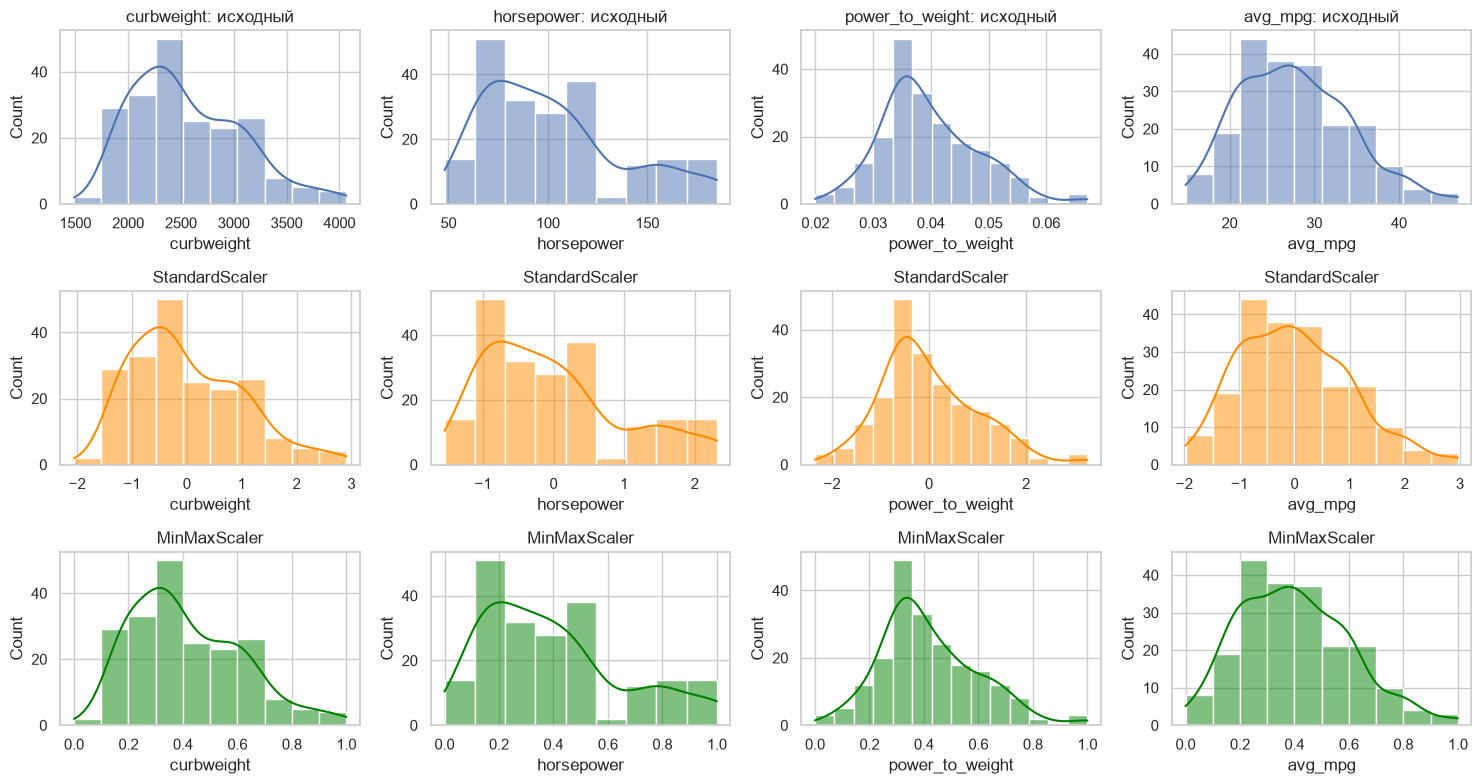

In [18]:
# Сравнение до / после на примере нескольких признаков
show = ["curbweight", "horsepower", "power_to_weight", "avg_mpg"]
fig, axes = plt.subplots(3, len(show), figsize=(15, 8))
for j, c in enumerate(show):
    sns.histplot(df_enc[c], kde=True, ax=axes[0, j]);  axes[0, j].set_title(f"{c}: исходный")
    sns.histplot(df_std[c], kde=True, ax=axes[1, j], color="darkorange"); axes[1, j].set_title("StandardScaler")
    sns.histplot(df_mm[c], kde=True, ax=axes[2, j], color="green"); axes[2, j].set_title("MinMaxScaler")
save_show("08_scaling_compare")

In [19]:
# Сохранение результатов
df_enc.to_csv(f"{OUT_DIR}/scrap_price_clean_encoded.csv", index=False)
df_std.to_csv(f"{OUT_DIR}/scrap_price_standardized.csv", index=False)
df_mm.to_csv(f"{OUT_DIR}/scrap_price_minmax.csv", index=False)
print("Готово. Файлы сохранены в", OUT_DIR)

Готово. Файлы сохранены в output
